# 01 · Data audit and exploratory profile

We begin with the raw Kaggle file and verify the dataset contract before any modeling. The goal is to preserve the source file unchanged while making the ingestion logic explicit and reproducible.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
ROOT

PosixPath('/mnt/data/wine_lda_portfolio')

In [2]:
import pandas as pd
from src.data import load_raw, audit_data, clean_data
from src.config import FEATURES
raw = load_raw()
audit_data(raw)

{'rows': 178,
 'columns': 14,
 'predictors': 13,
 'missing_cells': 0,
 'duplicate_rows': 0,
 'classes': 3,
 'class_counts': {'1': 59, '2': 71, '3': 48}}

In [3]:
clean = clean_data(raw)
clean.head()

,cultivar,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315,proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


## Class balance

The target is numerically coded as 1, 2 and 3, but represents three categorical cultivars.

In [4]:
clean['cultivar'].value_counts().sort_index().to_frame('count')

,count
cultivar,
1,59
2,71
3,48


## Descriptive statistics

The 13 predictors use different physical scales, which motivates standardization before interpreting discriminant coefficients.

In [5]:
clean[FEATURES].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.001,0.812,11.03,12.362,13.050,13.678,14.83
malic_acid,178.0,2.336,1.117,0.74,1.602,1.865,3.082,5.80
ash,178.0,2.367,0.274,1.36,2.210,2.360,2.558,3.23
alcalinity_of_ash,178.0,19.495,3.340,10.60,17.200,19.500,21.500,30.00
magnesium,178.0,99.742,14.282,70.00,88.000,98.000,107.000,162.00
total_phenols,178.0,2.295,0.626,0.98,1.742,2.355,2.800,3.88
flavanoids,178.0,2.029,0.999,0.34,1.205,2.135,2.875,5.08
nonflavanoid_phenols,178.0,0.362,0.124,0.13,0.270,0.340,0.438,0.66
proanthocyanins,178.0,1.591,0.572,0.41,1.250,1.555,1.950,3.58
color_intensity,178.0,5.058,2.318,1.28,3.220,4.690,6.200,13.00


{
  "audit": {
    "rows": 178,
    "columns": 14,
    "predictors": 13,
    "missing_cells": 0,
    "duplicate_rows": 0,
    "classes": 3,
    "class_counts": {
      "1": 59,
      "2": 71,
      "3": 48
    }
  },
  "lda": {
    "original_dimensions": 13,
    "reduced_dimensions": 2,
    "explained_discriminant_variance": [
      0.6874788878860784,
      0.3125211121139216
    ],
    "cumulative": 1.0
  },
  "holdout": {
    "accuracy": 1.0,
    "balanced_accuracy": 1.0,
    "macro_f1": 1.0,
    "n_train": 133,
    "n_test": 45
  },
  "cross_validation": {
    "folds": 10,
    "accuracy_mean": 0.9941176470588236,
    "accuracy_std": 0.018601633295108118
  }
}


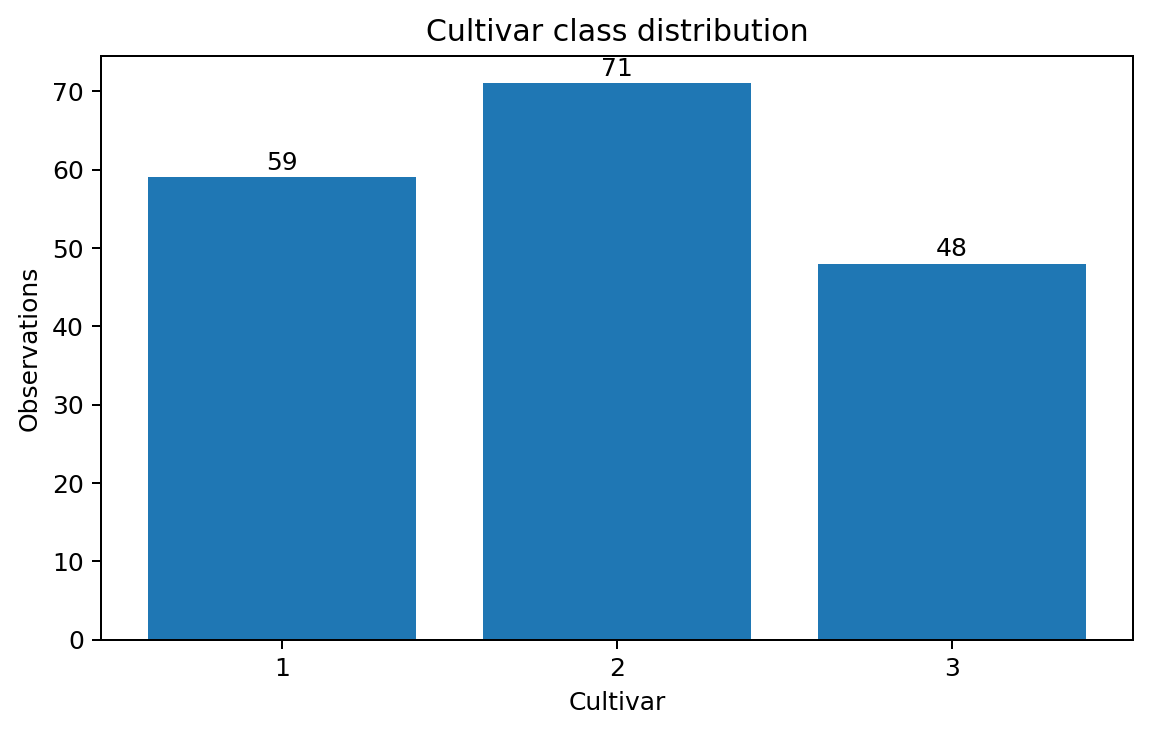

In [6]:
from IPython.display import Image, display
from src.run_analysis import main
main()
display(Image(filename=str(ROOT/'outputs/figures/class_balance.png')))